[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github.com/DEDJIABDOUL/omicaa-lab-MLforBiologistes/blob/main/notebooks/05_validation_et_optimisation.ipynb)

# Notebook 05 : validation croisée, optimisation des hyperparamètres et évaluation finale

**Omicaa Lab | Machine Learning et Deep Learning pour les biologistes** | Auteur : DEDJI ABDOUL BATINOU

## Introduction scientifique

Un score obtenu sur un seul jeu de validation dépend du hasard du découpage. La validation croisée remplace cette estimation unique par plusieurs estimations, ce qui permet de mesurer la variabilité d'un score et non seulement sa valeur. L'optimisation des hyperparamètres consomme de l'information sur les données : elle doit donc rester séparée de l'évaluation finale, faute de quoi la performance annoncée est optimiste. Ce notebook sépare strictement les deux phases, et se termine par une évaluation unique sur le jeu de test réservé.

## Objectifs techniques

1. Comparer des modèles par validation croisée stratifiée avec plusieurs métriques et mesurer la variabilité des scores.
2. Optimiser des hyperparamètres avec GridSearchCV et RandomizedSearchCV, sans utiliser le jeu de test.
3. Estimer sans biais la performance d'une procédure d'optimisation par validation croisée imbriquée.
4. Montrer pourquoi un partitionnement aléatoire est inadapté à des observations groupées (patients, lots).
5. Évaluer une fois le modèle retenu, quantifier l'incertitude, sauvegarder et recharger le pipeline.

## Prérequis

* Notebooks 03 et 04 terminés.

## Résultat attendu

Un modèle final sélectionné par une règle fixée à l'avance, évalué une seule fois sur le jeu de test avec intervalles de confiance, sauvegardé, rechargé et vérifié.

## 1. Contrôle de l'environnement et partitionnement

In [1]:
import sys, platform, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import json, warnings
from pathlib import Path
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.3
NumPy       : 2.4.4
pandas      : 3.0.2
Matplotlib  : 3.10.8
scikit-learn: 1.8.0


In [2]:
import joblib
from scipy.stats import randint
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GroupKFold,
                                     cross_validate, cross_val_score, cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, precision_recall_curve, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.calibration import CalibrationDisplay

FIG, RES, MOD = Path("figures"), Path("results"), Path("models")
for d in (FIG, RES, MOD): d.mkdir(exist_ok=True)
ROUGE, CYAN, NOIR, GRIS = "#FF0000", "#0097B2", "#000000", "#8A8A8A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9.5})

bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = (bunch.target == 0).astype(int).rename("maligne")            # 1 = maligne = classe positive
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

assert X_train.shape == (455, 30) and X_test.shape == (114, 30)
assert set(X_train.index).isdisjoint(X_test.index) and "maligne" not in X.columns
JOURNAL = {"notebook": "05", "graine": SEED, "sklearn": sklearn.__version__}
print("Le jeu de test (X_test, y_test) ne sera utilisé qu'à la section 9.")

Le jeu de test (X_test, y_test) ne sera utilisé qu'à la section 9.


## 2. Validation croisée stratifiée

Dans une validation croisée à $k$ plis, les données d'entraînement sont découpées en $k$ parties de tailles voisines. Pour chaque pli, le modèle est **ajusté sur $k-1$ parties** et **évalué sur la partie restante**. On obtient $k$ scores : leur moyenne estime la performance attendue et leur écart type mesure la **variabilité** liée au découpage.

* `StratifiedKFold` conserve la proportion des classes dans chaque pli.
* `shuffle=True` mélange avant le découpage ; avec `random_state`, le découpage reste reproductible.
* Le pipeline complet est ajusté à chaque pli : le `StandardScaler` n'apprend que sur les $k-1$ parties d'entraînement.

On utilise le **même objet `cv`** pour tous les modèles afin qu'ils soient évalués sur des plis identiques et que la comparaison soit appariée.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modeles = {
    "Référence": Pipeline([("modele", DummyClassifier(strategy="most_frequent"))]),
    "Régression logistique": Pipeline([("scaler", StandardScaler()), ("modele", LogisticRegression(max_iter=1000))]),
    "Arbre de décision": Pipeline([("modele", DecisionTreeClassifier(random_state=SEED))]),
    "Forêt aléatoire": Pipeline([("modele", RandomForestClassifier(n_estimators=200, random_state=SEED))]),
}
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

resultats_cv, scores_f1 = {}, {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")     # le modèle de référence n'a pas de précision définie sur certains plis
    for nom, m in modeles.items():
        r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
        resultats_cv[nom] = {k.replace("test_", ""): (r[k].mean(), r[k].std()) for k in r if k.startswith("test_")}
        scores_f1[nom] = r["test_f1"]

tableau = pd.DataFrame({nom: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in d.items()} for nom, d in resultats_cv.items()}).T
print(tableau)

                            accuracy      precision         recall  \
Référence              0.626 ± 0.000  0.000 ± 0.000  0.000 ± 0.000   
Régression logistique  0.974 ± 0.015  0.977 ± 0.028  0.953 ± 0.040   
Arbre de décision      0.923 ± 0.033  0.900 ± 0.041  0.894 ± 0.061   
Forêt aléatoire        0.963 ± 0.015  0.964 ± 0.011  0.935 ± 0.039   

                                  f1        roc_auc  
Référence              0.000 ± 0.000  0.500 ± 0.000  
Régression logistique  0.964 ± 0.021  0.996 ± 0.005  
Arbre de décision      0.896 ± 0.045  0.917 ± 0.038  
Forêt aléatoire        0.949 ± 0.021  0.989 ± 0.007  


Le format `moyenne ± écart type` rend visible ce que la validation unique du notebook 04 cachait : l'incertitude. Quand l'écart entre deux modèles est du même ordre que cet écart type, on ne peut pas affirmer que l'un est meilleur. Les écarts types portent sur 5 plis et sont eux-mêmes imprécis.

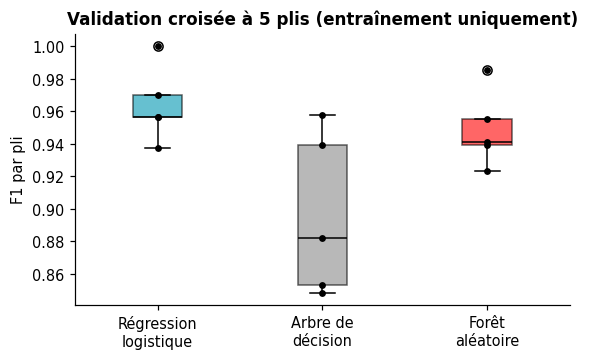

In [4]:
fig, ax = plt.subplots(figsize=(5.8, 3.2))
noms = ["Régression logistique", "Arbre de décision", "Forêt aléatoire"]
bp = ax.boxplot([scores_f1[n] for n in noms], tick_labels=["Régression\nlogistique", "Arbre de\ndécision", "Forêt\naléatoire"],
                patch_artist=True, medianprops=dict(color=NOIR))
for patch, c in zip(bp["boxes"], [CYAN, GRIS, ROUGE]):
    patch.set_facecolor(c); patch.set_alpha(0.6)
for i, n in enumerate(noms, 1):
    ax.scatter(np.full(5, i), scores_f1[n], color=NOIR, s=12, zorder=3)
ax.set_ylabel("F1 par pli")
ax.set_title("Validation croisée à 5 plis (entraînement uniquement)")
fig.savefig(FIG / "fig_cv_boxplot.png", dpi=170, bbox_inches="tight")
plt.show()

JOURNAL["cv_5plis"] = {n: {m: [round(float(mu), 4), round(float(sd), 4)] for m, (mu, sd) in d.items()} for n, d in resultats_cv.items()}

### 2.1 Variabilité due au découpage

La moyenne d'une validation croisée dépend elle-même de la graine qui définit les plis. On répète la procédure avec dix graines différentes pour la régression logistique.

In [5]:
moy_par_graine = []
for g in range(10):
    s = cross_val_score(modeles["Régression logistique"], X_train, y_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=g), scoring="accuracy")
    moy_par_graine.append(s.mean())
moy_par_graine = np.array(moy_par_graine)
print("moyennes d'accuracy selon la graine des plis :", moy_par_graine.round(3))
print(f"étendue : {moy_par_graine.min():.3f} à {moy_par_graine.max():.3f}")
JOURNAL["variabilite_graine_logreg"] = [round(float(moy_par_graine.min()), 4), round(float(moy_par_graine.max()), 4)]

moyennes d'accuracy selon la graine des plis : [0.978 0.971 0.974 0.969 0.971 0.971 0.974 0.976 0.976 0.969]
étendue : 0.969 à 0.978


La validation croisée **répétée** (`RepeatedStratifiedKFold`) moyenne ces effets et donne une estimation plus stable, au prix d'un temps de calcul multiplié.

## 3. Choisir la métrique de sélection

Le critère d'optimisation doit découler de la question scientifique et être fixé **avant** l'exploration.

* L'**AUC** évalue la capacité à classer les observations selon un score, indépendamment du seuil. C'est un critère stable pour comparer des configurations.
* Le **rappel** est essentiel pour ne pas manquer de tumeurs malignes, mais il peut être maximisé trivialement en prédisant toujours « maligne ».
* Le **F1** équilibre précision et rappel pour un seuil donné.

**Décision.** Les configurations sont sélectionnées sur l'AUC en validation croisée. Le seuil de décision est choisi ensuite, séparément, pour atteindre un rappel cible (section 8). Précision, rappel et F1 sont enregistrés pour chaque configuration à titre de suivi.

## 4. Recherche exhaustive : `GridSearchCV`

`GridSearchCV` ajuste le pipeline pour chaque combinaison d'une grille d'hyperparamètres, l'évalue par validation croisée, puis **réajuste** la meilleure combinaison sur l'ensemble de l'entraînement (`refit`). Dans un pipeline, les hyperparamètres d'une étape se nomment `etape__parametre`.

In [6]:
scoring_gs = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"}

pipe_lr = Pipeline([("scaler", StandardScaler()), ("modele", LogisticRegression(max_iter=2000))])
grille_lr = {"modele__C": [0.001, 0.01, 0.1, 1, 10, 100]}
gs_lr = GridSearchCV(pipe_lr, grille_lr, scoring=scoring_gs, refit="roc_auc", cv=cv).fit(X_train, y_train)

res = pd.DataFrame(gs_lr.cv_results_)[["param_modele__C", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_recall", "mean_test_f1"]]
print(res.round(4).to_string(index=False))
print("\nmeilleure configuration :", gs_lr.best_params_, "| AUC CV =", round(gs_lr.best_score_, 4))

 param_modele__C  mean_test_roc_auc  std_test_roc_auc  mean_test_recall  mean_test_f1
           0.001             0.9857            0.0106            0.7000        0.8175
           0.010             0.9911            0.0090            0.8647        0.9234
           0.100             0.9949            0.0056            0.9353        0.9603
           1.000             0.9958            0.0047            0.9529        0.9640
          10.000             0.9943            0.0036            0.9412        0.9550
         100.000             0.9914            0.0052            0.9471        0.9472

meilleure configuration : {'modele__C': 1} | AUC CV = 0.9958


Un `C` très faible impose une forte régularisation et sous-ajuste, un `C` très élevé laisse les coefficients croître librement. L'AUC varie peu autour de l'optimum : plusieurs valeurs de `C` sont pratiquement équivalentes. Le « meilleur » `C` est donc moins important que la stabilité du plateau.

## 5. Recherche aléatoire : `RandomizedSearchCV`

Lorsque l'espace d'hyperparamètres est grand, une grille complète devient coûteuse. `RandomizedSearchCV` tire `n_iter` configurations au hasard dans des distributions. Elle explore souvent plus efficacement les hyperparamètres qui comptent vraiment.

In [7]:
pipe_rf = Pipeline([("modele", RandomForestClassifier(random_state=SEED))])
distributions = {"modele__n_estimators": randint(100, 400),
                 "modele__max_depth": [3, 5, 8, None],
                 "modele__max_features": ["sqrt", "log2", 0.3],
                 "modele__min_samples_leaf": randint(1, 6)}
rs_rf = RandomizedSearchCV(pipe_rf, distributions, n_iter=12, scoring=scoring_gs, refit="roc_auc",
                           cv=cv, random_state=SEED).fit(X_train, y_train)

res_rf = pd.DataFrame(rs_rf.cv_results_).sort_values("rank_test_roc_auc")
cols = ["param_modele__n_estimators", "param_modele__max_depth", "param_modele__max_features",
        "param_modele__min_samples_leaf", "mean_test_roc_auc", "std_test_roc_auc"]
print(res_rf[cols].head(5).round(4).to_string(index=False))
print("\nmeilleure configuration :", rs_rf.best_params_, "| AUC CV =", round(rs_rf.best_score_, 4))

 param_modele__n_estimators param_modele__max_depth param_modele__max_features  param_modele__min_samples_leaf  mean_test_roc_auc  std_test_roc_auc
                        287                       8                       log2                               4             0.9885            0.0056
                        121                    None                       sqrt                               1             0.9884            0.0069
                        364                    None                       log2                               2             0.9883            0.0060
                        291                    None                       log2                               2             0.9882            0.0066
                        234                    None                       sqrt                               3             0.9878            0.0074

meilleure configuration : {'modele__max_depth': 8, 'modele__max_features': 'log2', 'modele__min_samples_leaf': 

## 6. Validation croisée imbriquée : l'estimation honnête de la procédure

Le score `best_score_` d'une recherche est **optimiste** : la meilleure configuration a été choisie *parce qu'elle avait le meilleur score* sur ces mêmes plis. Pour estimer la performance de la **procédure complète** (choix des hyperparamètres inclus), on imbrique deux boucles : une boucle interne qui optimise, une boucle externe qui évalue sur des données que l'optimisation n'a pas vues.

In [8]:
cv_externe = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
cv_interne = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 2)

recherche_interne = GridSearchCV(pipe_lr, grille_lr, scoring="roc_auc", cv=cv_interne)
auc_imbriquee = cross_val_score(recherche_interne, X_train, y_train, cv=cv_externe, scoring="roc_auc")
print(f"AUC validation croisée imbriquée : {auc_imbriquee.mean():.4f} ± {auc_imbriquee.std():.4f}")
print(f"AUC non imbriquée (best_score_)   : {gs_lr.best_score_:.4f}")
JOURNAL["auc_imbriquee_logreg"] = [round(float(auc_imbriquee.mean()), 4), round(float(auc_imbriquee.std()), 4)]
JOURNAL["auc_non_imbriquee_logreg"] = round(float(gs_lr.best_score_), 4)

AUC validation croisée imbriquée : 0.9945 ± 0.0042
AUC non imbriquée (best_score_)   : 0.9958


Sur ce jeu de données, l'écart est faible parce que l'espace de recherche est petit (six valeurs d'un seul hyperparamètre) et que le signal est fort. Il serait plus important avec de nombreux hyperparamètres, un petit effectif ou un signal faible. Ne pas observer d'optimisme ici ne dispense pas de la procédure.

## 7. Observations groupées : quand le découpage aléatoire trompe

Si plusieurs observations proviennent d'un même patient, d'un même centre ou d'un même lot expérimental, elles sont **corrélées**. Un découpage aléatoire place des observations d'un même patient à la fois dans l'entraînement et dans la validation : le modèle peut alors reconnaître le patient au lieu d'apprendre la biologie. `GroupKFold` impose que tous les échantillons d'un groupe restent du même côté.

**Expérience sur données simulées.** Les données ci-dessous sont **entièrement synthétiques** et construites pour que l'étiquette n'ait *aucun lien* avec les mesures : chaque patient a une signature propre, tirée au hasard, indépendante de sa classe. Toute performance supérieure au hasard ne peut donc venir que de l'identification du patient.

découpage aléatoire (patients mélangés) : accuracy = 0.996
GroupKFold (patients séparés)           : accuracy = 0.546
part de la classe majoritaire           : 0.6


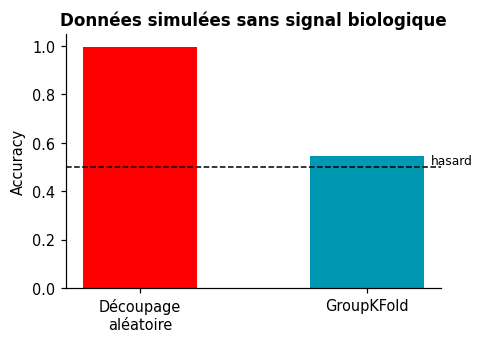

In [9]:
rng = np.random.default_rng(SEED)
n_pat, n_rep, p = 40, 6, 20
id_patient = np.repeat(np.arange(n_pat), n_rep)
signature = rng.normal(0, 2.0, size=(n_pat, p))                  # identité du patient, sans lien avec la classe
classe_patient = rng.integers(0, 2, size=n_pat)                  # étiquette tirée indépendamment des signatures
X_g = signature[id_patient] + rng.normal(0, 0.5, size=(n_pat * n_rep, p))
y_g = classe_patient[id_patient]

rf_g = RandomForestClassifier(n_estimators=100, random_state=SEED)
acc_alea = cross_val_score(rf_g, X_g, y_g, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
acc_groupe = cross_val_score(rf_g, X_g, y_g, cv=GroupKFold(n_splits=5), groups=id_patient, scoring="accuracy")
print(f"découpage aléatoire (patients mélangés) : accuracy = {acc_alea.mean():.3f}")
print(f"GroupKFold (patients séparés)           : accuracy = {acc_groupe.mean():.3f}")
print("part de la classe majoritaire           :", round(max(y_g.mean(), 1 - y_g.mean()), 3))
JOURNAL["groupes_simules"] = {"aleatoire": round(float(acc_alea.mean()), 4), "groupkfold": round(float(acc_groupe.mean()), 4)}

fig, ax = plt.subplots(figsize=(4.4, 3.0))
ax.bar(["Découpage\naléatoire", "GroupKFold"], [acc_alea.mean(), acc_groupe.mean()], color=[ROUGE, CYAN], width=0.5)
ax.axhline(0.5, color=NOIR, ls="--", lw=1); ax.text(1.28, 0.51, "hasard", fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("Accuracy")
ax.set_title("Données simulées sans signal biologique")
fig.savefig(FIG / "fig_groupes.png", dpi=170, bbox_inches="tight")
plt.show()

Le découpage aléatoire annonce une performance élevée alors qu'il n'existe **aucun signal** à apprendre ; `GroupKFold` ramène le score au niveau du hasard (autour de 0,5 ; la classe majoritaire représente 0,60 des observations). Cette expérience est une construction pédagogique, mais le mécanisme est réel : pour des données à plusieurs prélèvements par individu, le choix du découpage conditionne la validité de l'évaluation. Le jeu Wisconsin utilisé ici ne fournit pas d'identifiant patient dans la copie de scikit-learn : l'hypothèse d'indépendance des observations **ne peut pas être vérifiée** et constitue une limite.

## 8. Sélection du modèle final selon une règle fixée à l'avance

**Règle.** On retient le modèle de plus haute AUC moyenne en validation croisée. Si l'écart avec l'autre modèle est inférieur à l'écart type du meilleur, on retient le plus simple (la régression logistique), car une différence inférieure à la variabilité n'est pas démontrée.

Cette règle est écrite et appliquée **avant** toute consultation du jeu de test.

In [10]:
def moy_std(g):
    i = g.best_index_
    return g.cv_results_["mean_test_roc_auc"][i], g.cv_results_["std_test_roc_auc"][i]

(m_lr, s_lr), (m_rf, s_rf) = moy_std(gs_lr), moy_std(rs_rf)
print(f"Régression logistique : AUC CV = {m_lr:.4f} ± {s_lr:.4f}")
print(f"Forêt aléatoire       : AUC CV = {m_rf:.4f} ± {s_rf:.4f}")

(meilleur_nom, m_best, s_best), (autre_nom, m_aut, _) = sorted(
    [("Régression logistique", m_lr, s_lr), ("Forêt aléatoire", m_rf, s_rf)], key=lambda t: -t[1])
if (m_best - m_aut) < s_best:
    choix = "Régression logistique"
else:
    choix = meilleur_nom
print("modèle retenu :", choix)
modele_final = gs_lr.best_estimator_ if choix == "Régression logistique" else rs_rf.best_estimator_
JOURNAL["selection"] = {"logreg": [round(float(m_lr), 4), round(float(s_lr), 4)],
                        "foret": [round(float(m_rf), 4), round(float(s_rf), 4)],
                        "retenu": choix, "hyperparametres": {k: (None if v is None else (v.item() if hasattr(v, "item") else v))
                                                             for k, v in (gs_lr if choix == "Régression logistique" else rs_rf).best_params_.items()}}

Régression logistique : AUC CV = 0.9958 ± 0.0047
Forêt aléatoire       : AUC CV = 0.9885 ± 0.0056
modèle retenu : Régression logistique


### 8.1 Choix du seuil de décision sans le jeu de test

Un classifieur probabiliste prédit « maligne » lorsque la probabilité dépasse un **seuil** (0,5 par défaut). En dépistage, on peut préférer un seuil plus bas qui augmente le rappel au prix de la précision. On fixe ici une **exigence a priori** (rappel d'au moins 0,97 en validation croisée) et on cherche le seuil le plus élevé qui la satisfait, à partir de prédictions obtenues par validation croisée **sur l'entraînement**.

In [11]:
proba_cv = cross_val_predict(modele_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, seuils = precision_recall_curve(y_train, proba_cv)
admissibles = np.where(rec[:-1] >= 0.97)[0]
seuil = float(seuils[admissibles[-1]])
print(f"seuil retenu : {seuil:.3f} | rappel CV = {rec[admissibles[-1]]:.3f} | précision CV = {prec[admissibles[-1]]:.3f}")
JOURNAL["seuil"] = {"valeur": round(seuil, 4), "rappel_cv": round(float(rec[admissibles[-1]]), 4), "precision_cv": round(float(prec[admissibles[-1]]), 4)}

seuil retenu : 0.315 | rappel CV = 0.971 | précision CV = 0.954


## 9. Évaluation finale, une seule fois, sur le jeu de test

À ce stade, le modèle (famille, hyperparamètres, seuil) est entièrement figé. Le jeu de test est utilisé **une fois** pour estimer la performance sur des données jamais vues. Si les résultats déçoivent, on n'a pas le droit de revenir modifier le modèle en regardant le test : cela transformerait le test en jeu de validation et ferait perdre sa valeur à l'estimation.

In [12]:
proba_test = modele_final.predict_proba(X_test)[:, 1]
pred_05 = (proba_test >= 0.5).astype(int)
assert np.array_equal(pred_05, modele_final.predict(X_test))          # cohérence entre predict et predict_proba

def metriques(y_vrai, pred, proba):
    return {"accuracy": accuracy_score(y_vrai, pred), "precision": precision_score(y_vrai, pred, zero_division=0),
            "recall": recall_score(y_vrai, pred, zero_division=0), "f1": f1_score(y_vrai, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_vrai, proba)}

m05 = metriques(y_test, pred_05, proba_test)
pred_seuil = (proba_test >= seuil).astype(int)
mseuil = metriques(y_test, pred_seuil, proba_test)
print(pd.DataFrame({"seuil 0,5": m05, f"seuil {seuil:.3f}": mseuil}).round(3))

for nom, p in [("seuil 0,5", pred_05), (f"seuil {seuil:.3f}", pred_seuil)]:
    vn, fp, fn, vp = confusion_matrix(y_test, p).ravel()
    print(f"{nom:12s} VN={vn} FP={fp} FN={fn} VP={vp}")
print()
print(classification_report(y_test, pred_05, target_names=["bénigne", "maligne"], digits=3))

           seuil 0,5  seuil 0.315
accuracy       0.965        0.974
precision      0.975        0.976
recall         0.929        0.952
f1             0.951        0.964
roc_auc        0.996        0.996
seuil 0,5    VN=71 FP=1 FN=3 VP=39
seuil 0.315  VN=71 FP=1 FN=2 VP=40

              precision    recall  f1-score   support

     bénigne      0.959     0.986     0.973        72
     maligne      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



**Incertitude.** Un jeu de test de 114 observations dont environ 42 malignes donne des estimations bruitées : un faux négatif de plus ou de moins change le rappel de plus de deux points. On quantifie cette incertitude par un **bootstrap percentile** : on rééchantillonne le jeu de test avec remise, on recalcule la métrique, et on prend les quantiles 2,5 % et 97,5 %. Le modèle n'est pas réajusté.

In [13]:
rng = np.random.default_rng(SEED)
yt, pt = y_test.values, proba_test
boot = {"recall": [], "roc_auc": [], "accuracy": []}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[i])) < 2: continue
    boot["recall"].append(recall_score(yt[i], (pt[i] >= 0.5).astype(int)))
    boot["roc_auc"].append(roc_auc_score(yt[i], pt[i]))
    boot["accuracy"].append(accuracy_score(yt[i], (pt[i] >= 0.5).astype(int)))
ic = {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in boot.items()}
for k, (a, b) in ic.items():
    print(f"{k:9s} IC95 % (bootstrap) = [{a:.3f} ; {b:.3f}]")
JOURNAL["test"] = {"seuil_0_5": {k: round(float(v), 4) for k, v in m05.items()},
                   "seuil_cv": {k: round(float(v), 4) for k, v in mseuil.items()},
                   "ic95": {k: [round(float(a), 4), round(float(b), 4)] for k, (a, b) in ic.items()},
                   "confusion_0_5": dict(zip(["VN", "FP", "FN", "VP"], map(int, confusion_matrix(y_test, pred_05).ravel()))),
                   "confusion_seuil": dict(zip(["VN", "FP", "FN", "VP"], map(int, confusion_matrix(y_test, pred_seuil).ravel())))}

recall    IC95 % (bootstrap) = [0.841 ; 1.000]
roc_auc   IC95 % (bootstrap) = [0.986 ; 1.000]
accuracy  IC95 % (bootstrap) = [0.930 ; 0.991]


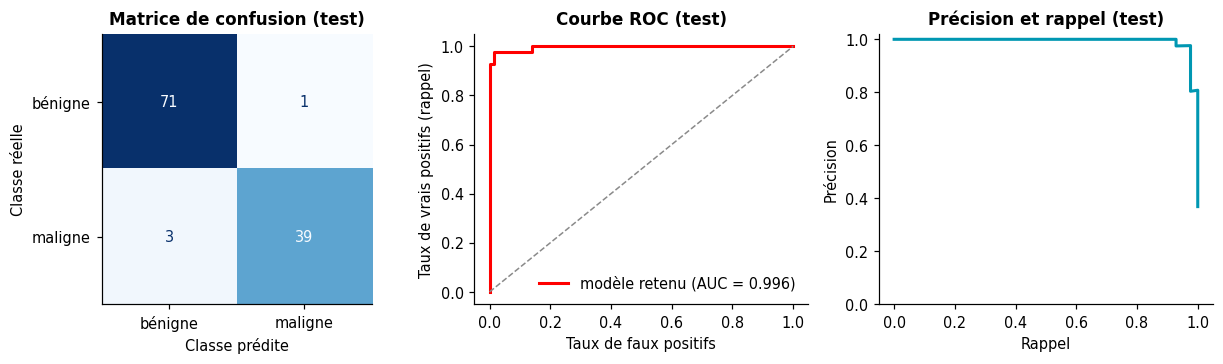

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_05, display_labels=["bénigne", "maligne"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Matrice de confusion (test)"); axes[0].grid(False)
axes[0].set_xlabel("Classe prédite"); axes[0].set_ylabel("Classe réelle")
fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[1].plot(fpr, tpr, color=ROUGE, lw=2, label=f"modèle retenu (AUC = {m05['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Taux de vrais positifs (rappel)")
axes[1].legend(frameon=False, loc="lower right"); axes[1].set_title("Courbe ROC (test)")
p_, r_, _ = precision_recall_curve(y_test, proba_test)
axes[2].plot(r_, p_, color=CYAN, lw=2)
axes[2].set_xlabel("Rappel"); axes[2].set_ylabel("Précision"); axes[2].set_ylim(0.0, 1.02)
axes[2].set_title("Précision et rappel (test)")
fig.tight_layout()
fig.savefig(FIG / "fig_test_final.png", dpi=170, bbox_inches="tight")
plt.show()

**Calibration.** Une bonne discrimination n'implique pas que les probabilités soient fiables. Une prédiction « 0,9 » est calibrée si environ 90 % des observations qui reçoivent ce score sont réellement positives. Avec un jeu de test de cette taille, la courbe de calibration est très approximative : elle sert à repérer un défaut grossier, non à certifier une calibration.

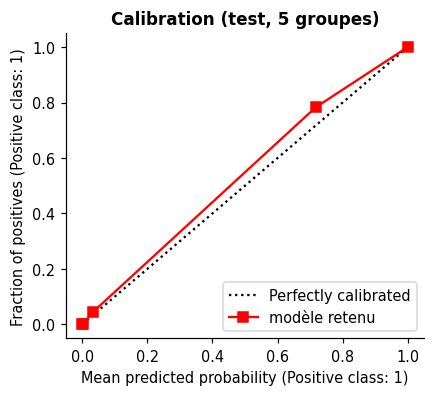

In [15]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
CalibrationDisplay.from_predictions(y_test, proba_test, n_bins=5, strategy="quantile", ax=ax, color=ROUGE, name="modèle retenu")
ax.set_title("Calibration (test, 5 groupes)")
fig.savefig(FIG / "fig_calibration.png", dpi=170, bbox_inches="tight")
plt.show()

## 10. Sauvegarde, rechargement et prédiction

Sauvegarder le **pipeline entier** (et non le seul estimateur) garantit que les mêmes transformations sont appliquées aux futures données. `joblib` sérialise l'objet. Attention : un fichier sérialisé n'est fiable qu'avec la **même version de scikit-learn**, et il ne faut jamais charger un fichier de provenance inconnue (la désérialisation peut exécuter du code).

In [16]:
chemin = MOD / "modele_final.joblib"
joblib.dump(modele_final, chemin)
(MOD / "modele_final_metadonnees.json").write_text(json.dumps({
    "modele": choix, "sklearn": sklearn.__version__, "classe_positive": "maligne (1)", "seuil_defaut": 0.5,
    "seuil_rappel_cible": round(seuil, 4), "colonnes_attendues": list(X.columns), "graine": SEED}, ensure_ascii=False, indent=2))

recharge = joblib.load(chemin)
assert np.array_equal(recharge.predict(X_test), modele_final.predict(X_test))
assert np.allclose(recharge.predict_proba(X_test), modele_final.predict_proba(X_test))
print("modèle rechargé : prédictions identiques sur", len(X_test), "observations")

nouveau = X_test.iloc[[0]]                           # une observation, conservée sous forme de DataFrame (1, 30)
print("probabilité de tumeur maligne :", round(float(recharge.predict_proba(nouveau)[0, 1]), 4), "| vérité :", int(y_test.iloc[0]))

# Validation de l'entrée au moment de la prédiction : une colonne manquante doit provoquer une erreur explicite.
try:
    recharge.predict(nouveau.drop(columns=["mean radius"]))
except ValueError as e:
    print("entrée invalide refusée :", str(e).splitlines()[0])

modèle rechargé : prédictions identiques sur 114 observations
probabilité de tumeur maligne : 0.0004 | vérité : 0
entrée invalide refusée : The feature names should match those that were passed during fit.


## 11. Limites à énoncer

* **Effectif.** 569 observations : les estimations sont bruitées, comme l'indiquent les intervalles de confiance.
* **Indépendance.** Aucun identifiant patient : l'hypothèse d'observations indépendantes n'est pas vérifiable.
* **Optimisation.** Elle améliore la performance estimée sur ces données ; elle ne garantit ni la robustesse à un autre centre, un autre instrument ou une autre population, ni la validité biologique.
* **Validité externe.** Une performance interne élevée n'est pas une validation clinique. Il faudrait des données indépendantes, acquises par d'autres équipes, puis un essai prospectif.
* **Association et causalité.** Un modèle prédictif exploite des associations statistiques. Il ne démontre aucun mécanisme.

In [17]:
(RES / "nb05.json").write_text(json.dumps(JOURNAL, ensure_ascii=False, indent=2, default=str))
print("Journal enregistré dans", RES / "nb05.json")

Journal enregistré dans results/nb05.json


## 12. Exercices progressifs

**Exercice 1.** Refaites la validation croisée de la régression logistique avec 10 plis. L'écart type de l'accuracy augmente-t-il ou diminue-t-il ? Pourquoi ?

*Solution de l'exercice 1*

In [18]:
for k in (5, 10):
    s = cross_val_score(modeles["Régression logistique"], X_train, y_train, cv=StratifiedKFold(k, shuffle=True, random_state=SEED), scoring="accuracy")
    print(f"{k:2d} plis : moyenne {s.mean():.3f} | écart type {s.std():.3f} | observations par pli de validation : {len(X_train) // k}")

 5 plis : moyenne 0.974 | écart type 0.015 | observations par pli de validation : 91
10 plis : moyenne 0.976 | écart type 0.023 | observations par pli de validation : 45


**Exercice 2.** Relancez la recherche de `C` en sélectionnant sur le rappel (`refit="recall"`). La valeur retenue est-elle différente ? Comment l'expliquez-vous ?

*Solution de l'exercice 2*

In [19]:
gs_rappel = GridSearchCV(pipe_lr, grille_lr, scoring=scoring_gs, refit="recall", cv=cv).fit(X_train, y_train)
print("C retenu sur l'AUC :", gs_lr.best_params_["modele__C"], "| C retenu sur le rappel :", gs_rappel.best_params_["modele__C"])

C retenu sur l'AUC : 1 | C retenu sur le rappel : 1


**Exercice 3.** Calculez l'intervalle de confiance bootstrap à 95 % de la **précision** du modèle final sur le test, et comparez sa largeur à celle du rappel.

*Solution de l'exercice 3*

In [20]:
rng = np.random.default_rng(0)
vals = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    vals.append(precision_score(yt[i], (pt[i] >= 0.5).astype(int), zero_division=0))
print("IC95 % précision :", np.percentile(vals, [2.5, 97.5]).round(3), "| IC95 % rappel :", np.round(ic["recall"], 3))

IC95 % précision : [0.919 1.   ] | IC95 % rappel : [0.841 1.   ]


**Exercice 4.** Pourquoi réajuste-t-on le meilleur modèle sur *tout* le jeu d'entraînement après la recherche (`refit=True`) plutôt que de conserver le modèle d'un des plis ?

*Solution de l'exercice 4*

In [21]:
print("Chaque modèle de pli a vu seulement 80 % de l'entraînement. Une fois la configuration choisie, on dispose d'une estimation fiable de sa qualité "
      "par validation croisée, et on l'ajuste sur 100 % de l'entraînement pour exploiter toute l'information disponible.")
print("taille d'un pli d'ajustement :", int(len(X_train) * 0.8), "| entraînement complet :", len(X_train))

Chaque modèle de pli a vu seulement 80 % de l'entraînement. Une fois la configuration choisie, on dispose d'une estimation fiable de sa qualité par validation croisée, et on l'ajuste sur 100 % de l'entraînement pour exploiter toute l'information disponible.
taille d'un pli d'ajustement : 364 | entraînement complet : 455


## 13. Synthèse des compétences acquises

* Mesurer la performance et sa variabilité par validation croisée stratifiée, sur des plis communs aux modèles.
* Optimiser des hyperparamètres avec `GridSearchCV` et `RandomizedSearchCV` sans consulter le test.
* Estimer la performance d'une procédure d'optimisation par validation croisée imbriquée.
* Reconnaître une situation de données groupées et choisir un découpage adapté.
* Fixer à l'avance une règle de sélection, choisir un seuil sans le test, évaluer une fois, quantifier l'incertitude.
* Sauvegarder un pipeline, le recharger et valider les entrées au moment de la prédiction.

**Suite.** Le notebook 06 introduit un réseau de neurones dense avec TensorFlow et Keras, évalué selon un protocole compatible avec celui-ci.